# Power System Load-Type Prediction

## Objective
Build and evaluate classifiers that predict `Load_Type` (`Light_Load`, `Medium_Load`, or `Maximum_Load`) from historical power-system measurements and timestamp-derived features.

**Evaluation protocol:** the final month (December 2018) is held out for testing. November 2018 is used for model selection/validation. December results are not used to select the model.

This notebook compares time-only, electrical-only, combined, and trailing-usage feature sets. Full-day activity features are included as a **retrospective** experiment; they use later readings from the same day and are not suitable for real-time prediction at the timestamp.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
CLASSES = ["Light_Load", "Medium_Load", "Maximum_Load"]
sns.set_theme(style="whitegrid")

# Support running from either the project root or a notebooks/ directory.
candidates = [Path("../data/load_data.csv"), Path("data/load_data.csv"),
              Path("load_data.csv"), Path("/mnt/data/load_data.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find load_data.csv. Put it in data/ or ../data/.")
print("Using:", DATA_PATH.resolve())

Using: /home/sahil/assignment-2 1/data/load_data.csv


## 1. Load and clean the data

The duplicate timestamp is resolved by retaining the row with the fewest missing fields. Corrupted precision and physically impossible power-factor values are marked missing. `NSM` is rebuilt from the timestamp because the timestamp is the reliable source of time-of-day information.

The row-level repair formulas use the electrical identity relating active/reactive power and power factor. Any remaining missing values are imputed inside each model pipeline using training data only.

In [2]:
RENAME = {
    "Lagging_Current_Reactive.Power_kVarh": "Lag_kVarh",
    "Leading_Current_Reactive_Power_kVarh": "Lead_kVarh",
    "CO2(tCO2)": "CO2",
    "Lagging_Current_Power_Factor": "Lag_PF",
    "Leading_Current_Power_Factor": "Lead_PF",
}
VALUE_COLS = ["Usage_kWh", "Lag_kVarh", "Lead_kVarh", "CO2", "Lag_PF", "Lead_PF"]

raw = pd.read_csv(DATA_PATH).rename(columns=RENAME)
raw["Date_Time"] = pd.to_datetime(raw["Date_Time"], dayfirst=True, errors="coerce")
raw = raw.dropna(subset=["Date_Time"])
n_missing = raw.drop(columns="Date_Time").isna().sum(axis=1)
df0 = (raw.assign(_n=n_missing).sort_values(["Date_Time", "_n"])
          .drop_duplicates("Date_Time", keep="first")
          .drop(columns="_n").set_index("Date_Time").sort_index())

assert df0.index.is_unique, "Timestamps should be unique after deduplication."
assert len(df0) == 35040, f"Expected 35,040 quarter-hour rows, got {len(df0)}"
assert (df0.index.to_series().diff().dropna() == pd.Timedelta("15min")).all()
print("Shape after deduplication:", df0.shape)
print("Date range:", df0.index.min(), "to", df0.index.max())
display(df0.head())

Shape after deduplication: (35040, 8)
Date range: 2018-01-01 00:00:00 to 2018-12-31 23:45:00


,Usage_kWh,Lag_kVarh,Lead_kVarh,CO2,Lag_PF,Lead_PF,NSM,Load_Type
Date_Time,,,,,,,,
2018-01-01 00:00:00,3.420000,3.46,0.0,0.0,70.30,291.49819,0.000000,Light_Load
2018-01-01 00:15:00,8.753692,2.95,0.0,0.0,73.21,100.00000,900.000000,Light_Load
2018-01-01 00:30:00,4.000000,4.46,0.0,0.0,66.77,100.00000,1800.000000,Light_Load
2018-01-01 00:45:00,3.240000,3.28,0.0,0.0,70.28,100.00000,8070.880991,Light_Load
2018-01-01 01:00:00,3.310000,3.56,0.0,0.0,68.09,100.00000,3600.000000,Light_Load


In [3]:
def spurious(s, decimals=2):
    x = s * (10 ** decimals)
    return ((x - np.round(x)).abs() > 1e-5) & s.notna()

def pf_from(u, q):
    den = np.sqrt(u**2 + q**2)
    return (100 * u / den).mask(den == 0, 0.0)

flag = pd.DataFrame({c: spurious(df0[c]) for c in VALUE_COLS})
print("Share of non-missing readings flagged for excess precision:")
display(flag.mean().rename("flagged_fraction").to_frame().round(3))

df_clean = df0.copy()
df_clean["NSM"] = (df_clean.index.hour * 3600 + df_clean.index.minute * 60).astype(float)
for c in VALUE_COLS:
    df_clean.loc[spurious(df_clean[c]), c] = np.nan
for c in ["Lag_PF", "Lead_PF"]:
    df_clean.loc[~df_clean[c].between(0, 100), c] = np.nan

# Rebuild readings where the formula is stable and enough information is present.
def repair_readings(data, min_q=1.0, max_pf=99.0):
    out = data.copy()
    for side in ("Lag", "Lead"):
        q, pf = f"{side}_kVarh", f"{side}_PF"
        can = out["Usage_kWh"].isna() & out[q].notna() & out[pf].notna()
        zero = can & (out[pf] == 0) & (out[q] > 0)
        out.loc[zero, "Usage_kWh"] = 0.0
        m = can & ~zero & (out[q] >= min_q) & (out[pf] > 0) & (out[pf] <= max_pf)
        out.loc[m, "Usage_kWh"] = (
            out.loc[m, q] * out.loc[m, pf] /
            np.sqrt(100.0**2 - out.loc[m, pf]**2)
        ).round(2)
    for side in ("Lag", "Lead"):
        q, pf = f"{side}_kVarh", f"{side}_PF"
        m = out[pf].isna() & out["Usage_kWh"].notna() & out[q].notna()
        out.loc[m, pf] = pf_from(out.loc[m, "Usage_kWh"], out.loc[m, q]).round(2)
        m = (out[q].isna() & out["Usage_kWh"].notna() &
             (out["Usage_kWh"] > 0) & out[pf].notna() &
             (out[pf] > 0) & (out[pf] <= max_pf))
        out.loc[m, q] = (
            out.loc[m, "Usage_kWh"] *
            np.sqrt((100.0 / out.loc[m, pf])**2 - 1)
        ).round(2)
    return out

df = repair_readings(df_clean)
print("Missing fraction before and after formula-based repair:")
display(pd.concat([df_clean[VALUE_COLS].isna().mean(),
                   df[VALUE_COLS].isna().mean()], axis=1,
                  keys=["after cleaning", "after repair"]).round(3))

Share of non-missing readings flagged for excess precision:


,flagged_fraction
Usage_kWh,0.096
Lag_kVarh,0.077
Lead_kVarh,0.032
CO2,0.039
Lag_PF,0.099
Lead_PF,0.095


Missing fraction before and after formula-based repair:


,after cleaning,after repair
Usage_kWh,0.140,0.036
Lag_kVarh,0.102,0.030
Lead_kVarh,0.065,0.043
CO2,0.052,0.052
Lag_PF,0.109,0.022
Lead_PF,0.137,0.016


## 2. Chronological train/validation/test split

November is the validation month for model selection. December is the final held-out test month. No December score is used to choose the model or feature set.

In [4]:
months = df.index.to_period("M")
test_month = months.max()
val_month = test_month - 1
SPLITS = {
    "validation": (months < val_month, months == val_month),
    "test": (months < test_month, months == test_month),
}
print("Training/validation boundary:", val_month)
print("Final test month:", test_month)
for name, (tr, ev) in SPLITS.items():
    print(f"{name}: train={tr.sum():,}, evaluation={ev.sum():,}")

Training/validation boundary: 2018-11
Final test month: 2018-12
validation: train=29,184, evaluation=2,880
test: train=32,064, evaluation=2,976


## 3. Feature engineering

- **A — Time only:** time of day, season, weekday and weekend.
- **B — Electrical only:** measured electrical and emissions features.
- **C — Time + day activity:** adds same-day daytime median and 90th-percentile usage. This is retrospective because it uses readings later in the day.
- **D — Time + trailing usage:** adds the rolling median from the previous six hours. This is the more appropriate feature set for sequential, real-time prediction because it uses only current/past readings.
- **E — Everything:** combines time, electrical, and full-day activity features; also retrospective.

`CO2` is retained in the electrical feature group for comparison, although EDA suggests it is largely redundant with usage.

In [5]:
TIME = ["minute_of_day", "is_winter", "weekday", "is_weekend"]
ELEC = ["Usage_kWh", "Lag_kVarh", "Lead_kVarh", "CO2", "Lag_PF", "Lead_PF"]

def build_features(d):
    f = pd.DataFrame(index=d.index)
    f["minute_of_day"] = d.index.hour * 60 + d.index.minute
    f["is_winter"] = ((d.index.month >= 11) | (d.index.month <= 2)).astype(int)
    f["weekday"] = d.index.dayofweek
    f["is_weekend"] = (f["weekday"] >= 5).astype(int)
    for c in ELEC:
        f[c] = d[c]
    daytime = d["Usage_kWh"].where((d.index.hour >= 10) & (d.index.hour <= 22))
    by_day = daytime.groupby(d.index.normalize())
    f["day_med"] = by_day.transform("median")
    f["day_p90"] = by_day.transform(lambda s: s.quantile(0.9))
    # Rolling window includes current and prior readings only; no future rows.
    f["usage_roll_med_6h"] = d["Usage_kWh"].rolling(24, min_periods=6).median()
    return f

feats = build_features(df)
FEATURE_SETS = {
    "A time only": TIME,
    "B electrical only": ELEC,
    "C time + day activity (retrospective)": TIME + ["day_med", "day_p90"],
    "D time + trailing usage (causal)": TIME + ["usage_roll_med_6h"],
    "E everything (retrospective)": TIME + ELEC + ["day_med", "day_p90"],
}
display(pd.DataFrame([{"feature_set": k, "n_features": len(v), "features": ", ".join(v)}
                      for k, v in FEATURE_SETS.items()]))

,feature_set,n_features,features
0,A time only,4,"minute_of_day, is_winter, weekday, is_weekend"
1,B electrical only,6,"Usage_kWh, Lag_kVarh, Lead_kVarh, CO2, Lag_PF,..."
2,C time + day activity (retrospective),6,"minute_of_day, is_winter, weekday, is_weekend,..."
3,D time + trailing usage (causal),5,"minute_of_day, is_winter, weekday, is_weekend,..."
4,E everything (retrospective),12,"minute_of_day, is_winter, weekday, is_weekend,..."


## 4. Train and compare models

The models are Logistic Regression, Random Forest, and Histogram Gradient Boosting. Imputation (and scaling for Logistic Regression) is fit within each model pipeline. Model/feature-set selection uses **November macro-F1**.

In [6]:
def make_models():
    return {
        "Logistic regression": make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            LogisticRegression(max_iter=2000, class_weight="balanced",
                               random_state=RANDOM_STATE)
        ),
        "Random forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                                   n_jobs=-1, class_weight="balanced",
                                   random_state=RANDOM_STATE)
        ),
        "Gradient boosting": make_pipeline(
            SimpleImputer(strategy="median"),
            HistGradientBoostingClassifier(class_weight="balanced",
                                           random_state=RANDOM_STATE)
        ),
    }

def evaluate(y, pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, pred, labels=CLASSES, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(y, pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
    }

rows = []
fitted_models = {}
predictions = {}
for split_name, (train_mask, eval_mask) in SPLITS.items():
    X_train, y_train = feats.loc[train_mask], df.loc[train_mask, "Load_Type"]
    X_eval, y_eval = feats.loc[eval_mask], df.loc[eval_mask, "Load_Type"]
    for feature_name, columns in FEATURE_SETS.items():
        for model_name, estimator in make_models().items():
            estimator.fit(X_train[columns], y_train)
            pred = pd.Series(estimator.predict(X_eval[columns]), index=y_eval.index)
            fitted_models[(split_name, feature_name, model_name)] = estimator
            predictions[(split_name, feature_name, model_name)] = pred
            rows.append({
                "split": split_name, "feature_set": feature_name, "model": model_name,
                **evaluate(y_eval, pred)
            })

results = pd.DataFrame(rows)
validation_results = results[results["split"] == "validation"].copy()
display(validation_results.sort_values("f1_macro", ascending=False).reset_index(drop=True).round(4))

,split,feature_set,model,accuracy,precision_macro,recall_macro,f1_macro
0,validation,C time + day activity (retrospective),Random forest,1.0000,1.0000,1.0000,1.0000
1,validation,C time + day activity (retrospective),Gradient boosting,1.0000,1.0000,1.0000,1.0000
2,validation,E everything (retrospective),Gradient boosting,0.9958,0.9948,0.9947,0.9947
3,validation,E everything (retrospective),Random forest,0.9663,0.9596,0.9534,0.9559
4,validation,D time + trailing usage (causal),Random forest,0.9444,0.9651,0.9309,0.9451
5,validation,D time + trailing usage (causal),Gradient boosting,0.9420,0.9637,0.9286,0.9430
6,validation,A time only,Gradient boosting,0.9417,0.9454,0.9397,0.9424
7,validation,A time only,Random forest,0.9417,0.9481,0.9370,0.9422
8,validation,B electrical only,Random forest,0.6382,0.5916,0.5880,0.5846
9,validation,B electrical only,Gradient boosting,0.6323,0.5944,0.5931,0.5785


## 5. Select the model and evaluate once on December

The best configuration is selected using November macro-F1. Its December performance is then reported on the held-out month. Since the full-day feature sets are retrospective, compare the best overall model with the best causal configuration from feature set D.

Selected by November validation:
Feature set: C time + day activity (retrospective)
Model: Random forest
November metrics: {'accuracy': 1.0, 'precision_macro': 1.0, 'recall_macro': 1.0, 'f1_macro': 1.0}


,split,feature_set,model,accuracy,precision_macro,recall_macro,f1_macro
0,test,E everything (retrospective),Gradient boosting,1.0000,1.0000,1.0000,1.0000
1,test,C time + day activity (retrospective),Gradient boosting,1.0000,1.0000,1.0000,1.0000
2,test,C time + day activity (retrospective),Random forest,1.0000,1.0000,1.0000,1.0000
3,test,E everything (retrospective),Random forest,0.9808,0.9747,0.9642,0.9680
4,test,D time + trailing usage (causal),Random forest,0.9684,0.9637,0.9662,0.9648
5,test,D time + trailing usage (causal),Gradient boosting,0.9634,0.9581,0.9595,0.9586
6,test,A time only,Random forest,0.8619,0.8305,0.9127,0.8576
7,test,A time only,Gradient boosting,0.8599,0.8286,0.9116,0.8560
8,test,E everything (retrospective),Logistic regression,0.7097,0.5814,0.5852,0.5764
9,test,B electrical only,Random forest,0.6371,0.5532,0.5590,0.5494


December test classification report for the selected model:
              precision    recall  f1-score   support

  Light_Load     1.0000    1.0000    1.0000      1744
 Medium_Load     1.0000    1.0000    1.0000       704
Maximum_Load     1.0000    1.0000    1.0000       528

    accuracy                         1.0000      2976
   macro avg     1.0000    1.0000    1.0000      2976
weighted avg     1.0000    1.0000    1.0000      2976



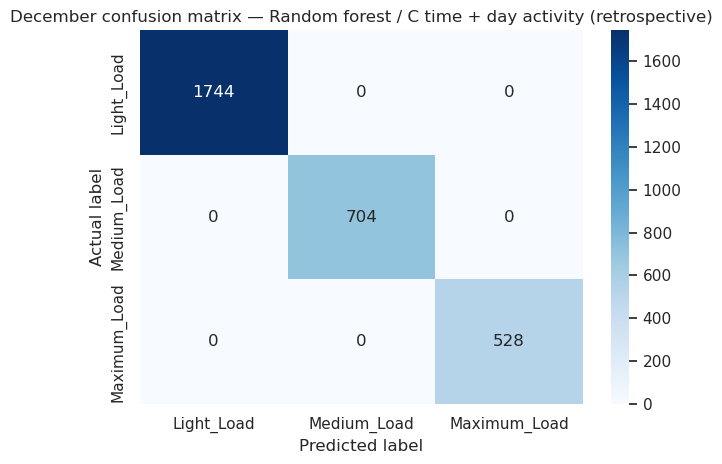

December dates with errors:


,incorrect_rows
Date_Time,


In [7]:
best_row = validation_results.sort_values(
    ["f1_macro", "accuracy"], ascending=False, kind="stable"
).iloc[0]
best_key = (best_row["feature_set"], best_row["model"])
print("Selected by November validation:")
print("Feature set:", best_key[0])
print("Model:", best_key[1])
print("November metrics:", best_row[["accuracy", "precision_macro", "recall_macro", "f1_macro"]].to_dict())

test_results = results[results["split"] == "test"].copy()
display(test_results.sort_values("f1_macro", ascending=False).reset_index(drop=True).round(4))

test_model = fitted_models[("test", best_key[0], best_key[1])]
test_pred = predictions[("test", best_key[0], best_key[1])]
y_test = df.loc[SPLITS["test"][1], "Load_Type"]
print("December test classification report for the selected model:")
print(classification_report(y_test, test_pred, labels=CLASSES, digits=4, zero_division=0))

cm = confusion_matrix(y_test, test_pred, labels=CLASSES)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(f"December confusion matrix — {best_key[1]} / {best_key[0]}")
plt.tight_layout()
plt.show()

errors_by_day = (test_pred != y_test).groupby(test_pred.index.normalize()).sum()
print("December dates with errors:")
display(errors_by_day[errors_by_day > 0].rename("incorrect_rows").to_frame())

## 6. Real-time-oriented model comparison

A model using full-day activity features can look excellent because it sees the whole day. For an operational prediction made at each timestamp, use the causal feature set D and compare it directly with the selected retrospective model. This is a more honest view of what can be known at prediction time.

In [8]:
causal_val = validation_results[
    validation_results["feature_set"] == "D time + trailing usage (causal)"
].sort_values("f1_macro", ascending=False)
print("Best causal model on November validation:")
display(causal_val.head(1).round(4))

causal_best = causal_val.iloc[0]
causal_key = (causal_best["feature_set"], causal_best["model"])
causal_test = test_results[
    (test_results["feature_set"] == causal_key[0]) &
    (test_results["model"] == causal_key[1])
]
print("Corresponding December test metrics:")
display(causal_test.round(4))

Best causal model on November validation:


,split,feature_set,model,accuracy,precision_macro,recall_macro,f1_macro
10,validation,D time + trailing usage (causal),Random forest,0.9444,0.9651,0.9309,0.9451


Corresponding December test metrics:


,split,feature_set,model,accuracy,precision_macro,recall_macro,f1_macro
25,test,D time + trailing usage (causal),Random forest,0.9684,0.9637,0.9662,0.9648


## 7. Feature importance using validation data only

Permutation importance is computed on November validation data, not December, to keep the final test month reserved for final evaluation. The plot below uses the best model's feature set, if supported by the estimator.

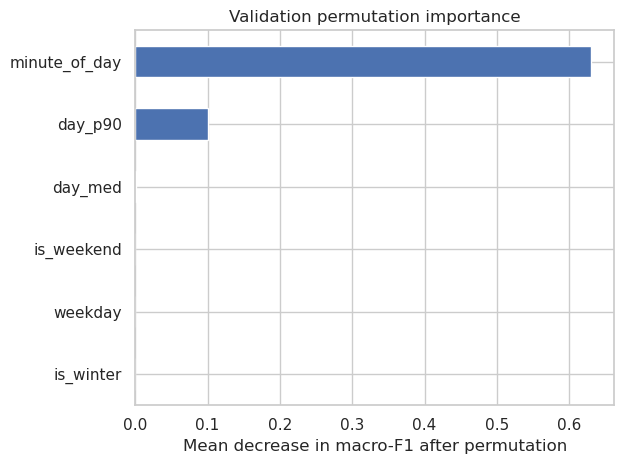

In [9]:
from sklearn.inspection import permutation_importance

val_train_mask, val_mask = SPLITS["validation"]
selected_columns = FEATURE_SETS[best_key[0]]
importance_model = fitted_models[("validation", best_key[0], best_key[1])]
X_val = feats.loc[val_mask, selected_columns]
y_val = df.loc[val_mask, "Load_Type"]
perm = permutation_importance(
    importance_model, X_val, y_val, n_repeats=3,
    random_state=RANDOM_STATE, scoring="f1_macro"
)
imp = pd.Series(perm.importances_mean, index=selected_columns).sort_values()
imp.plot.barh()
plt.xlabel("Mean decrease in macro-F1 after permutation")
plt.title("Validation permutation importance")
plt.tight_layout()
plt.show()

## 8. Example prediction on an unseen row

This example uses a held-out December row and the selected model's required feature columns. It demonstrates the prediction API; the reported December metrics above remain the evaluation summary.

In [10]:
sample_X = feats.loc[y_test.index[0], FEATURE_SETS[best_key[0]]].to_frame().T
sample_y = y_test.iloc[0]
sample_pred = test_model.predict(sample_X)[0]
print("Timestamp:", y_test.index[0])
print("Actual class (for demonstration):", sample_y)
print("Predicted class:", sample_pred)
display(sample_X)

Timestamp: 2018-12-01 00:00:00
Actual class (for demonstration): Light_Load
Predicted class: Light_Load


,minute_of_day,is_winter,weekday,is_weekend,day_med,day_p90
2018-12-01,0.0,1.0,5.0,1.0,4.79,27.94


## 9. Conclusions and limitations

- The notebook trains multiple classifiers and selects the configuration using November validation macro-F1.
- December is reserved as the final chronological test month.
- Report accuracy, macro-precision, macro-recall and macro-F1 together, plus the class-wise classification report and confusion matrix.
- Same-day median and 90th-percentile usage features are **retrospective**: they depend on later readings from the same day. Do not describe results using those features as real-time prediction performance.
- Feature set D uses a trailing six-hour usage median and is the more appropriate experiment for timestamp-by-timestamp deployment.
- Perfect scores, if observed, should be reported as results on this dataset and split—not as a guarantee of future performance. The dataset covers one year, so the test set represents only one month.

## Save the trained model for reuse

The model configuration is selected using November validation results. The fitted `test_model` below was trained on all observations before December, then evaluated on December. Save that fitted estimator together with its expected feature columns and metadata so it can be loaded without retraining.

**Important:** Feature set C/E uses full-day activity and is retrospective. The saved estimator expects already-engineered feature columns; see `predict_load_type.py` for the inference interface and limitations.


In [14]:
import joblib
from pathlib import Path

ARTIFACT_DIR = Path.home() / "assignment-2 1" / "models"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

selected_feature_set, selected_model_name = best_key
selected_columns = FEATURE_SETS[selected_feature_set]

model_artifact = {
    "estimator": test_model,
    "model_name": selected_model_name,
    "feature_set": selected_feature_set,
    "feature_columns": selected_columns,
    "classes": CLASSES,
    "random_state": RANDOM_STATE,
    "training_data": "January-November 2018 (December held out for final test)",
    "selection_rule": "Highest November validation macro-F1; accuracy breaks ties",
    "retrospective_features": any(c in selected_columns for c in ["day_med", "day_p90"]),
    "notes": (
        "Estimator expects a pandas DataFrame containing feature_columns in the recorded order. "
        "day_med/day_p90 require readings from later in the same day and are not real-time features."
    ),
}
artifact_path = ARTIFACT_DIR / "load_type_model.joblib"
joblib.dump(model_artifact, artifact_path)
print("Saved trained model:", artifact_path.resolve())
print("Model:", selected_model_name)
print("Feature set:", selected_feature_set)
print("Required input features:", selected_columns)
print("Retrospective features:", model_artifact["retrospective_features"])


Saved trained model: /home/sahil/assignment-2 1/models/load_type_model.joblib
Model: Random forest
Feature set: C time + day activity (retrospective)
Required input features: ['minute_of_day', 'is_winter', 'weekday', 'is_weekend', 'day_med', 'day_p90']
Retrospective features: True
